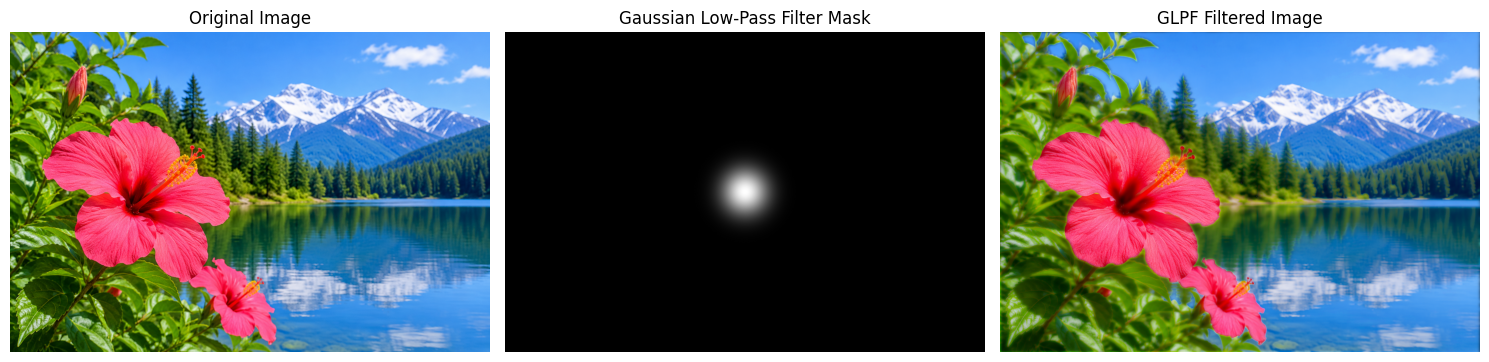

Gaussian Low-Pass Filtering Completed Successfully!


In [2]:
# Gaussian Low-Pass Filter (GLPF)
import cv2
import numpy as np
import matplotlib.pyplot as plt

image = cv2.imread("image.jpg")

if image is None:
    raise FileNotFoundError("Image not found!")

image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

hsv = cv2.cvtColor(image, cv2.COLOR_RGB2HSV)

H, S, V = cv2.split(hsv)

F = np.fft.fft2(V)
F_shift = np.fft.fftshift(F)

rows, cols = V.shape
crow, ccol = rows // 2, cols // 2

u = np.arange(rows) - crow
v = np.arange(cols) - ccol
U, V_grid = np.meshgrid(v, u)

D = np.sqrt(U**2 + V_grid**2)

D0 = 50

H_filter = np.exp(-(D**2) / (2 * D0**2))

G = F_shift * H_filter

G_ishift = np.fft.ifftshift(G)
img_back = np.fft.ifft2(G_ishift)

filtered_V = np.clip(np.real(img_back), 0, 255)
filtered_V = filtered_V.astype(np.uint8)

filtered_hsv = cv2.merge((H, S, filtered_V))

filtered_image = cv2.cvtColor(
    filtered_hsv, cv2.COLOR_HSV2RGB
)

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(image)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(H_filter, cmap="gray")
plt.title("Gaussian Low-Pass Filter Mask")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(filtered_image)
plt.title("GLPF Filtered Image")
plt.axis("off")

plt.tight_layout()
plt.show()

cv2.imwrite(
    "GLPF_filtered_image.jpg",
    cv2.cvtColor(filtered_image, cv2.COLOR_RGB2BGR)
)

print("Gaussian Low-Pass Filtering Completed Successfully!")
